# Airport Operations Analysis: Flight Activity and Weather Conditions

**Airport:** Frankfurt Airport (FRA / EDDF), Germany  
**Study period:** 15–28 September 2026 (14 complete UTC days)  
**Language:** Python  

## Project question
How does hourly flight activity at Frankfurt Airport vary with temperature, precipitation, wind speed, and reported weather conditions?

The airport was set to Frankfurt after the initial Almaty (UAAA) query returned no flight records for the test period, while a diagnostic query returned records for Frankfurt (EDDF). This keeps the analysis based on observed data rather than treating a missing dataset as zero activity.

This is an exploratory analysis of observed flight events and reanalysis weather. It can identify patterns or associations, but it cannot establish that weather caused a change in flight activity. OpenSky reports inferred ADS-B flight records, not airline schedules, official delay/cancellation data, or passenger counts.

### Data sources
1. **OpenSky Network REST API** — airport arrival and departure records. Historical access may require an OpenSky API client; credentials are entered at runtime and are never written to this notebook.
2. **Open-Meteo Historical Weather API** — hourly weather at the airport coordinates.
3. **Static webpage scraped with Requests + BeautifulSoup** — [Frankfurt Airport on Wikipedia](https://en.wikipedia.org/wiki/Frankfurt_Airport). The scraper checks `robots.txt` before requesting the page.

### Workflow
Collect → inspect → clean → transform to hourly counts → merge on UTC hour → EDA → at least three labeled plots. The OpenSky API is queried one day at a time to stay within the endpoint's time-window limit. If historical access is denied, the notebook reports the issue rather than substituting fabricated flight records.

## 1. Imports and project configuration

In [1]:
from pathlib import Path
from datetime import datetime, date, time, timedelta, timezone
from getpass import getpass
from urllib.robotparser import RobotFileParser
import re
import time as time_module

import requests
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

AIRPORT_NAME = "Frankfurt Airport"
IATA_CODE = "FRA"
ICAO_CODE = "EDDF"
AIRPORT_PAGE = "https://en.wikipedia.org/wiki/Frankfurt_Airport"
START_DATE = "2026-09-15"
END_DATE = "2026-09-28"  # inclusive; both endpoints are complete historical dates
USER_AGENT = "AirportOperationsCourseProject/1.0 (educational research)"

print(f"Airport: {AIRPORT_NAME} ({IATA_CODE}/{ICAO_CODE})")
print(f"Study period: {START_DATE} through {END_DATE}")
print(f"Project folder: {PROJECT_DIR}")

Airport: Frankfurt Airport (FRA/EDDF)
Study period: 2026-09-15 through 2026-09-28
Project folder: c:\Users\Acer\Desktop\SIS_Data_colllection


## 2. Scrape airport information from a static webpage

In [2]:
def scrape_airport_page(url: str) -> dict:
    """Extract basic airport attributes from the Wikipedia infobox.

    The page is fetched only if robots.txt permits this user agent.
    """
    robots_url = "https://en.wikipedia.org/robots.txt"
    robots_response = requests.get(robots_url, headers={"User-Agent": USER_AGENT}, timeout=30)
    robots_response.raise_for_status()
    robots = RobotFileParser()
    robots.parse(robots_response.text.splitlines())
    if not robots.can_fetch(USER_AGENT, url):
        raise PermissionError(f"robots.txt does not permit scraping: {url}")

    response = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")
    infobox = soup.select_one("table.infobox")
    if infobox is None:
        raise ValueError("Could not find the airport infobox; the page layout may have changed.")

    attributes = {}
    for row in infobox.select("tr"):
        label = row.find("th", recursive=False)
        value = row.find("td", recursive=False)
        if label and value:
            key = " ".join(label.stripped_strings).strip().lower()
            val = " ".join(value.stripped_strings).strip()
            attributes[key] = val

    # The machine-readable coordinate span is more dependable than parsing DMS text.
    geo = soup.select_one("table.infobox span.geo")
    latitude, longitude = np.nan, np.nan
    if geo:
        parts = [p.strip() for p in geo.get_text(";", strip=True).split(";")]
        if len(parts) >= 2:
            latitude, longitude = float(parts[0]), float(parts[1])

    # Codes occur in the article's rendered text; scrape rather than hard-code them.
    page_text = soup.get_text(" ", strip=True)
    iata_match = re.search(r"IATA\s*:?\s*([A-Z]{3})\b", page_text)
    icao_match = re.search(r"ICAO\s*:?\s*([A-Z]{4})\b", page_text)

    return {
        "airport_name": AIRPORT_NAME,
        "iata_code": iata_match.group(1) if iata_match else IATA_CODE,
        "icao_code": icao_match.group(1) if icao_match else ICAO_CODE,
        "latitude": latitude,
        "longitude": longitude,
        "airport_type": attributes.get("airport type"),
        "owner": attributes.get("owner"),
        "operator": attributes.get("operator"),
        "serves": attributes.get("serves"),
        "location": attributes.get("location"),
        "elevation": attributes.get("elevation amsl"),
        "source_url": url,
        "retrieved_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }

airport_info = scrape_airport_page(AIRPORT_PAGE)
airport_df = pd.DataFrame([airport_info])
airport_df.to_csv(DATA_DIR / "airport_metadata.csv", index=False)
airport_df.T.rename(columns={0: "value"})

,value
airport_name,Frankfurt Airport
iata_code,FRA
icao_code,EDDF
latitude,50.03333
longitude,8.57056
airport_type,Public
owner,None
operator,None
serves,Frankfurt Rhine-Main
location,"Frankfurt , Hesse"


## 3. Collect arrivals and departures from OpenSky

OpenSky's REST API uses OAuth2 client credentials. Create an API client in your OpenSky account, then enter its ID and secret when prompted. **Do not paste secrets into a saved notebook or commit them to a public repository.** The API's airport arrival/departure endpoints return completed, inferred flights; they are not an airline timetable. Access and historical-data permissions can vary by account.

In [3]:
TOKEN_URL = "https://auth.opensky-network.org/auth/realms/opensky-network/protocol/openid-connect/token"
OPENSKY_BASE_URL = "https://opensky-network.org/api"

class OpenSkyClient:
    """Small OAuth2 client that refreshes its access token when necessary."""
    def __init__(self, client_id: str, client_secret: str):
        if not client_id or not client_secret:
            raise ValueError("Both OpenSky client ID and client secret are required.")
        self.client_id = client_id
        self.client_secret = client_secret
        self.token = None
        self.token_expires_at = 0.0
        self.session = requests.Session()

    def _refresh_token(self):
        response = self.session.post(
            TOKEN_URL,
            data={
                "grant_type": "client_credentials",
                "client_id": self.client_id,
                "client_secret": self.client_secret,
            },
            timeout=30,
        )
        response.raise_for_status()
        payload = response.json()
        self.token = payload["access_token"]
        self.token_expires_at = time_module.time() + int(payload.get("expires_in", 1800)) - 45

    def get_json(self, endpoint: str, params: dict):
        if not self.token or time_module.time() >= self.token_expires_at:
            self._refresh_token()
        url = f"{OPENSKY_BASE_URL}{endpoint}"
        response = self.session.get(
            url,
            params=params,
            headers={"Authorization": f"Bearer {self.token}"},
            timeout=45,
        )
        if response.status_code == 401:
            self._refresh_token()
            response = self.session.get(
                url,
                params=params,
                headers={"Authorization": f"Bearer {self.token}"},
                timeout=45,
            )
        if response.status_code == 404:
            return []  # OpenSky uses 404 for an interval with no matching flights.
        if response.status_code == 403:
            raise PermissionError(
                "OpenSky returned 403 Forbidden. Your account/API client may not have access "
                "to historical airport flight data. Check OpenSky access and try a permitted date range."
            )
        if response.status_code == 429:
            raise RuntimeError("OpenSky rate limit reached. Wait before retrying the collection cell.")
        response.raise_for_status()
        data = response.json()
        return data if isinstance(data, list) else []

# Credentials are requested interactively and are not saved in notebook source.
client_id = input("OpenSky API client ID: ").strip()
client_secret = getpass("OpenSky API client secret (hidden): ")
opensky = OpenSkyClient(client_id, client_secret)
print("OpenSky client initialized; secret is kept out of notebook cells.")

OpenSky client initialized; secret is kept out of notebook cells.


In [4]:
def fetch_opensky_airport_events(client: OpenSkyClient, airport_icao: str,
                                  start_date: str, end_date: str) -> pd.DataFrame:
    """Fetch airport arrivals/departures for inclusive dates, one UTC day per request."""
    first_day = date.fromisoformat(start_date)
    last_day = date.fromisoformat(end_date)
    if last_day < first_day:
        raise ValueError("END_DATE must be on or after START_DATE.")

    rows = []
    day = first_day
    while day <= last_day:
        begin_dt = datetime.combine(day, time.min, tzinfo=timezone.utc)
        end_dt = begin_dt + timedelta(days=1)
        params = {"airport": airport_icao, "begin": int(begin_dt.timestamp()),
                  "end": int(end_dt.timestamp())}

        for direction, endpoint in [("arrival", "/flights/arrival"),
                                    ("departure", "/flights/departure")]:
            try:
                day_rows = client.get_json(endpoint, params)
            except PermissionError:
                raise
            except requests.HTTPError as exc:
                raise RuntimeError(
                    f"OpenSky request failed for {direction} on {day}: {exc}. "
                    "Check credentials, endpoint limits, and account access."
                ) from exc
            for row in day_rows:
                row = dict(row)
                row["direction"] = direction
                row["requested_day_utc"] = day.isoformat()
                rows.append(row)
            time_module.sleep(0.25)  # modest pause between calls
        day += timedelta(days=1)

    columns = ["icao24", "firstSeen", "estDepartureAirport", "lastSeen",
               "estArrivalAirport", "callsign", "direction", "requested_day_utc"]
    result = pd.DataFrame(rows)
    for column in columns:
        if column not in result.columns:
            result[column] = pd.Series(dtype="object")
    return result[columns]

try:
    flights_raw = fetch_opensky_airport_events(opensky, ICAO_CODE, START_DATE, END_DATE)
    flights_raw.to_csv(DATA_DIR / "opensky_flights_raw.csv", index=False)
    print(f"Rows collected: {len(flights_raw):,}")
    display(flights_raw.head())
except (PermissionError, RuntimeError, requests.RequestException, ValueError) as exc:
    flights_raw = pd.DataFrame()
    print(f"Flight collection did not complete: {exc}")
    print("No flight records will be invented. Resolve API access, then rerun this section.")

Rows collected: 18,702


,icao24,firstSeen,estDepartureAirport,lastSeen,estArrivalAirport,callsign,direction,requested_day_utc
0,495290,1.789496e+09,LPPT,1789505203,EDDF,TAP57LK,arrival,2026-09-15
1,3c7985,1.789498e+09,LEPA,1789504887,EDDF,CFG6EW,arrival,2026-09-15
2,3c7422,1.789492e+09,NaN,1789504266,EDDF,TUI69E,arrival,2026-09-15
3,3c7983,1.789494e+09,NaN,1789504170,EDDF,CFG031,arrival,2026-09-15
4,400a0e,1.789500e+09,EGLL,1789504096,EDDF,BAW910N,arrival,2026-09-15


## 4. Collect hourly historical weather from Open-Meteo

In [5]:
def fetch_open_meteo_weather(latitude: float, longitude: float,
                              start_date: str, end_date: str) -> pd.DataFrame:
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation,wind_speed_10m,weather_code",
        "timezone": "UTC",
    }
    response = requests.get(url, params=params, headers={"User-Agent": USER_AGENT}, timeout=60)
    response.raise_for_status()
    payload = response.json()
    if "hourly" not in payload or "time" not in payload["hourly"]:
        raise ValueError(f"Unexpected Open-Meteo response: {payload}")
    weather = pd.DataFrame(payload["hourly"])
    weather["time_utc"] = pd.to_datetime(weather.pop("time"), utc=True, errors="coerce")
    weather = weather.rename(columns={
        "temperature_2m": "temperature_c",
        "precipitation": "precipitation_mm",
        "wind_speed_10m": "wind_speed_kmh",
        "weather_code": "weather_code_wmo",
    })
    for col in ["temperature_c", "precipitation_mm", "wind_speed_kmh", "weather_code_wmo"]:
        weather[col] = pd.to_numeric(weather[col], errors="coerce")
    return weather

weather_df = fetch_open_meteo_weather(
    airport_info["latitude"], airport_info["longitude"], START_DATE, END_DATE
)
weather_df.to_csv(DATA_DIR / "open_meteo_weather_raw.csv", index=False)
print(f"Weather rows: {len(weather_df):,}")
display(weather_df.head())
print("Weather units: temperature °C; precipitation mm/hour; wind km/h; WMO weather code.")

Weather rows: 336


,temperature_c,precipitation_mm,wind_speed_kmh,weather_code_wmo,time_utc
0,15.9,0.0,3.9,2,2026-09-15 00:00:00+00:00
1,15.7,0.0,2.9,0,2026-09-15 01:00:00+00:00
2,15.4,0.0,1.4,0,2026-09-15 02:00:00+00:00
3,14.8,0.0,1.4,0,2026-09-15 03:00:00+00:00
4,14.5,0.0,1.0,0,2026-09-15 04:00:00+00:00


Weather units: temperature °C; precipitation mm/hour; wind km/h; WMO weather code.


## 5. Clean and transform the flight data

In [6]:
def clean_flight_events(raw: pd.DataFrame) -> pd.DataFrame:
    """Normalize API fields and create a UTC event hour for airport operations."""
    if raw.empty:
        return pd.DataFrame(columns=[
            "icao24", "callsign", "direction", "origin_icao", "destination_icao",
            "first_seen_utc", "last_seen_utc", "event_time_utc", "event_hour_utc"
        ])

    df = raw.copy()
    df["first_seen_utc"] = pd.to_datetime(df["firstSeen"], unit="s", utc=True, errors="coerce")
    df["last_seen_utc"] = pd.to_datetime(df["lastSeen"], unit="s", utc=True, errors="coerce")
    df["event_time_utc"] = df["last_seen_utc"].where(
        df["direction"].eq("arrival"), df["first_seen_utc"]
    )
    df["event_hour_utc"] = df["event_time_utc"].dt.floor("h")
    df["icao24"] = df["icao24"].astype("string").str.lower().str.strip()
    df["callsign"] = df["callsign"].astype("string").str.strip()
    df["origin_icao"] = df["estDepartureAirport"].astype("string").str.upper().str.strip()
    df["destination_icao"] = df["estArrivalAirport"].astype("string").str.upper().str.strip()
    df["direction"] = df["direction"].astype("category")
    df = df.dropna(subset=["event_hour_utc", "direction"])
    df = df.drop_duplicates(subset=[
        "icao24", "first_seen_utc", "last_seen_utc", "direction"
    ]).reset_index(drop=True)
    keep = ["icao24", "callsign", "direction", "origin_icao", "destination_icao",
            "first_seen_utc", "last_seen_utc", "event_time_utc", "event_hour_utc"]
    return df[keep]

flights_df = clean_flight_events(flights_raw)
print("Cleaned rows:", len(flights_df))
if not flights_df.empty:
    display(flights_df.head())
    print("Missing values by column:")
    display(flights_df.isna().sum().to_frame("missing"))
else:
    print("No flight rows available yet; flight-dependent analysis will be skipped.")

Cleaned rows: 18702


,icao24,callsign,direction,origin_icao,destination_icao,first_seen_utc,last_seen_utc,event_time_utc,event_hour_utc
0,495290,TAP57LK,arrival,LPPT,EDDF,2026-09-15 18:15:03+00:00,2026-09-15 20:46:43+00:00,2026-09-15 20:46:43+00:00,2026-09-15 20:00:00+00:00
1,3c7985,CFG6EW,arrival,LEPA,EDDF,2026-09-15 18:53:23+00:00,2026-09-15 20:41:27+00:00,2026-09-15 20:41:27+00:00,2026-09-15 20:00:00+00:00
2,3c7422,TUI69E,arrival,<NA>,EDDF,2026-09-15 17:11:36+00:00,2026-09-15 20:31:06+00:00,2026-09-15 20:31:06+00:00,2026-09-15 20:00:00+00:00
3,3c7983,CFG031,arrival,<NA>,EDDF,2026-09-15 17:38:06+00:00,2026-09-15 20:29:30+00:00,2026-09-15 20:29:30+00:00,2026-09-15 20:00:00+00:00
4,400a0e,BAW910N,arrival,EGLL,EDDF,2026-09-15 19:23:30+00:00,2026-09-15 20:28:16+00:00,2026-09-15 20:28:16+00:00,2026-09-15 20:00:00+00:00


Missing values by column:


,missing
icao24,0
callsign,31
direction,0
origin_icao,1434
destination_icao,1271
first_seen_utc,7
last_seen_utc,0
event_time_utc,0
event_hour_utc,0


## 6. Merge weather and airport activity by UTC hour

In [7]:
def make_hourly_merged(weather: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """Join hourly weather to hourly airport event counts on the same UTC hour."""
    hourly_weather = weather.copy().sort_values("time_utc")
    if events.empty:
        # Keep counts missing (not zero) because unavailable data is not evidence of no flights.
        hourly_weather["arrivals"] = np.nan
        hourly_weather["departures"] = np.nan
        hourly_weather["total_operations"] = np.nan
        return hourly_weather

    counts = (events.groupby(["event_hour_utc", "direction"], observed=False)
                    .size().unstack(fill_value=0))
    counts = counts.rename(columns={"arrival": "arrivals", "departure": "departures"})
    for col in ["arrivals", "departures"]:
        if col not in counts.columns:
            counts[col] = 0
    counts = counts[["arrivals", "departures"]]
    merged = hourly_weather.merge(counts, left_on="time_utc", right_index=True, how="left")
    merged[["arrivals", "departures"]] = merged[["arrivals", "departures"]].fillna(0).astype(int)
    merged["total_operations"] = merged["arrivals"] + merged["departures"]
    return merged

hourly_df = make_hourly_merged(weather_df, flights_df)
hourly_df.to_csv(DATA_DIR / "hourly_weather_flight_activity.csv", index=False)
print(f"Hourly merged rows: {len(hourly_df):,}")
display(hourly_df.head())

Hourly merged rows: 336


,temperature_c,precipitation_mm,wind_speed_kmh,weather_code_wmo,time_utc,arrivals,departures,total_operations
0,15.9,0.0,3.9,2,2026-09-15 00:00:00+00:00,0,0,0
1,15.7,0.0,2.9,0,2026-09-15 01:00:00+00:00,1,0,1
2,15.4,0.0,1.4,0,2026-09-15 02:00:00+00:00,0,2,2
3,14.8,0.0,1.4,0,2026-09-15 03:00:00+00:00,27,7,34
4,14.5,0.0,1.0,0,2026-09-15 04:00:00+00:00,27,18,45


## 7. Basic exploratory data analysis

In [8]:
weather_columns = ["temperature_c", "precipitation_mm", "wind_speed_kmh", "weather_code_wmo"]
print("Weather descriptive statistics:")
display(weather_df[weather_columns].describe().T)

if flights_df.empty:
    print("Flight statistics are unavailable until OpenSky returns records.")
else:
    print("Flight counts by direction:")
    display(flights_df["direction"].value_counts().rename_axis("direction").to_frame("events"))
    print("Daily operation totals:")
    daily_counts = (hourly_df.assign(date_utc=hourly_df["time_utc"].dt.date)
                    .groupby("date_utc", as_index=False)[["arrivals", "departures", "total_operations"]]
                    .sum())
    display(daily_counts)

# A readable descriptive summary of weather codes, without interpreting them as airport disruptions.
weather_code_counts = weather_df["weather_code_wmo"].value_counts(dropna=False).sort_index()
display(weather_code_counts.rename_axis("WMO code").to_frame("hour_count"))

Weather descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
temperature_c,336.0,15.882143,4.933859,4.6,12.375,15.85,19.225,28.0
precipitation_mm,336.0,0.015476,0.098033,0.0,0.000,0.00,0.000,1.1
wind_speed_kmh,336.0,7.471726,3.880922,0.2,4.500,7.40,9.850,18.9
weather_code_wmo,336.0,3.604167,10.477318,0.0,0.000,1.00,3.000,55.0


Flight counts by direction:


,events
direction,
arrival,9381
departure,9321


Daily operation totals:


,date_utc,arrivals,departures,total_operations
0,2026-09-15,631,628,1259
1,2026-09-16,634,652,1286
2,2026-09-17,678,667,1345
3,2026-09-18,686,683,1369
4,2026-09-19,659,652,1311
5,2026-09-20,684,665,1349
6,2026-09-21,688,673,1361
7,2026-09-22,641,647,1288
8,2026-09-23,674,670,1344
9,2026-09-24,664,671,1335


,hour_count
WMO code,
0,117
1,60
2,56
3,88
51,11
53,3
55,1


## 8. Visualizations (created when flight data is available)

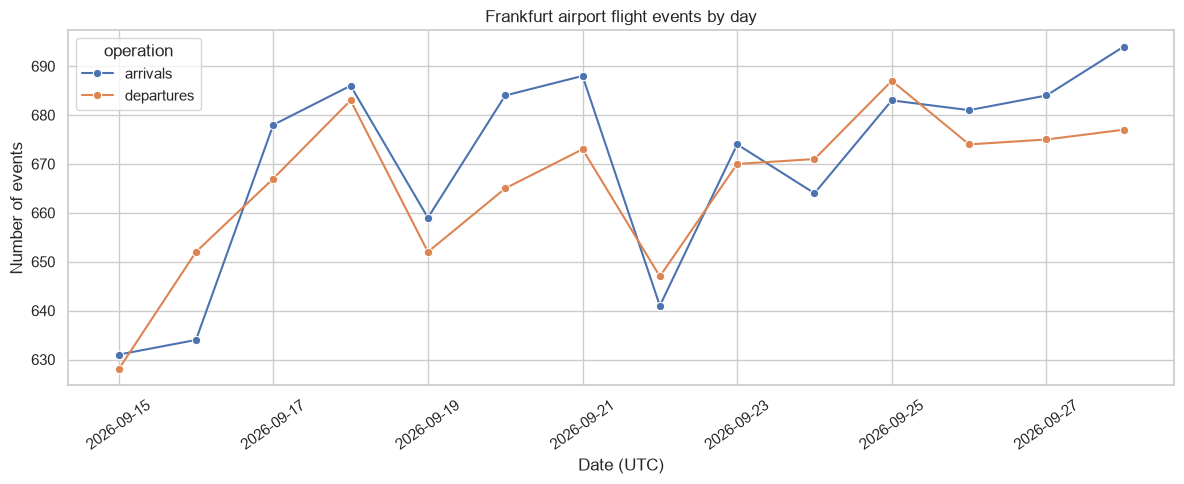

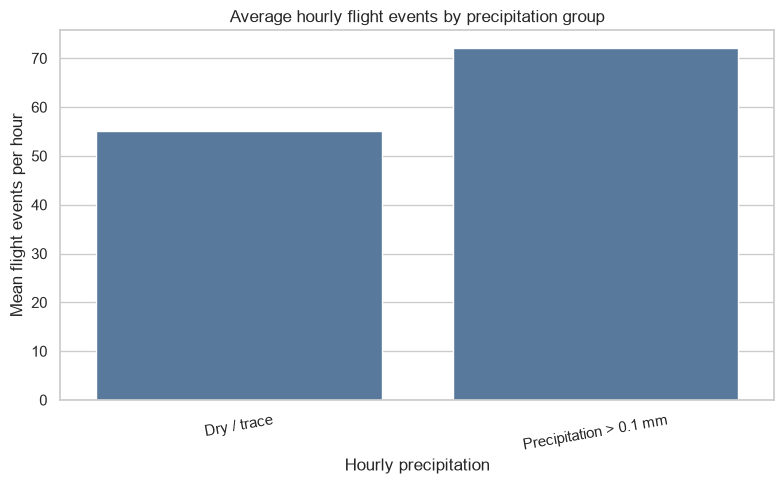

,precipitation_group,mean_hourly_operations,hourly_observations
0,Dry / trace,55.156442,326
1,Precipitation > 0.1 mm,72.100000,10


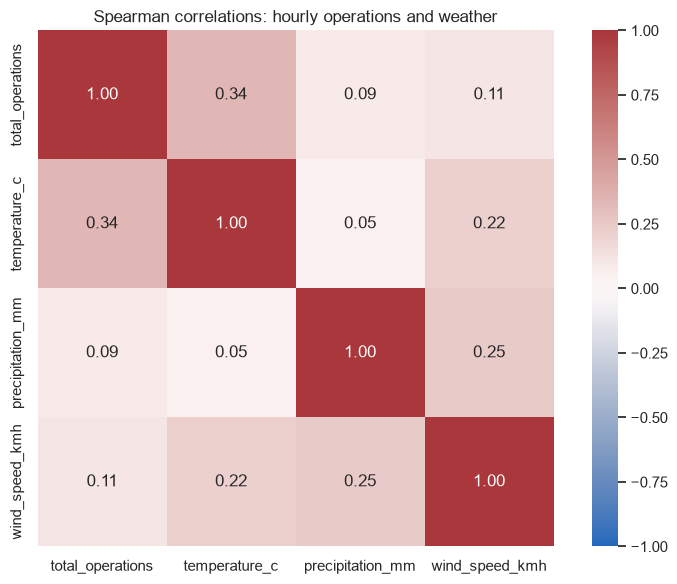

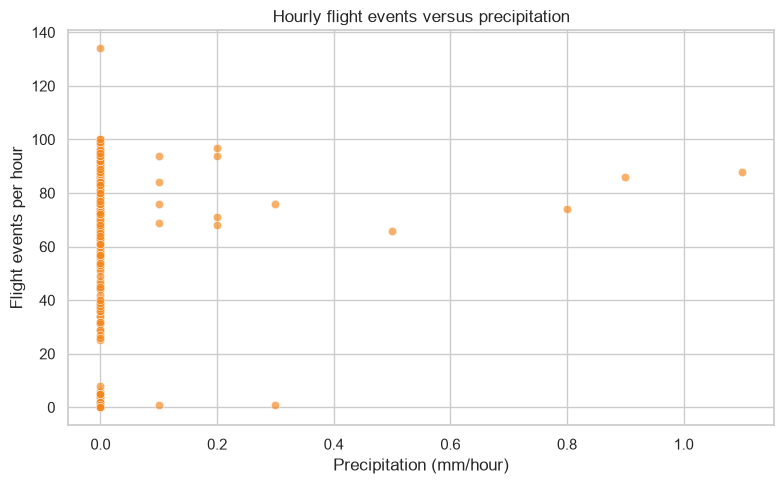

In [9]:
if flights_df.empty:
    print("Skipped flight/weather plots because the flight dataset is unavailable. Run the OpenSky section after access is resolved.")
else:
    # Daily arrivals and departures
    daily = (hourly_df.assign(date_utc=hourly_df["time_utc"].dt.date)
             .groupby("date_utc", as_index=False)[["arrivals", "departures"]].sum())
    fig, ax = plt.subplots(figsize=(12, 5))
    daily_plot = daily.melt("date_utc", var_name="operation", value_name="flight events")
    sns.lineplot(data=daily_plot, x="date_utc", y="flight events", hue="operation",
                 marker="o", ax=ax)
    ax.set(title="Frankfurt airport flight events by day", xlabel="Date (UTC)", ylabel="Number of events")
    ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "01_daily_arrivals_departures.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Average hourly operations under dry versus precipitation hours
    plot_data = hourly_df.copy()
    plot_data["precipitation_group"] = np.where(
        plot_data["precipitation_mm"].fillna(0) > 0.1, "Precipitation > 0.1 mm", "Dry / trace"
    )
    summary = (plot_data.groupby("precipitation_group", as_index=False, observed=False)
               .agg(mean_hourly_operations=("total_operations", "mean"),
                    hourly_observations=("total_operations", "count")))
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=summary, x="precipitation_group", y="mean_hourly_operations", ax=ax, color="#4C78A8")
    ax.set(title="Average hourly flight events by precipitation group",
           xlabel="Hourly precipitation", ylabel="Mean flight events per hour")
    ax.tick_params(axis="x", rotation=10)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "02_operations_by_precipitation.png", dpi=160, bbox_inches="tight")
    plt.show()
    display(summary)

    # Correlation heatmap; correlations are descriptive, not causal.
    corr_cols = ["total_operations", "temperature_c", "precipitation_mm", "wind_speed_kmh"]
    corr = hourly_df[corr_cols].corr(method="spearman", min_periods=10)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title("Spearman correlations: hourly operations and weather")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "03_weather_operations_correlation.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Supplemental scatter plot to inspect the precipitation/operations relationship.
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=hourly_df, x="precipitation_mm", y="total_operations",
                    alpha=0.65, ax=ax, color="#F58518")
    ax.set(title="Hourly flight events versus precipitation",
           xlabel="Precipitation (mm/hour)", ylabel="Flight events per hour")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "04_precipitation_scatter.png", dpi=160, bbox_inches="tight")
    plt.show()

## 9. Interpretation and report notes

After running the notebook, use the actual outputs to complete the 1–2 page report. Report the collection period, source URLs, number of records retrieved, cleaning decisions, merge key (UTC hour), and the three most relevant visual findings. Explicitly state if an API returned an error or incomplete data. Do not describe correlation as causation, and do not interpret OpenSky-derived records as official delays or scheduled operations.

### Questions to answer from the results
- How many arrivals and departures were successfully collected? Were any dates missing?
- What are the typical hourly and daily operation counts?
- Which weather variables show the strongest (if any) association with hourly activity?
- Is the precipitation comparison based on enough wet hours to be informative?
- What are the important limitations (single airport, short period, inferred ADS-B coverage, hourly aggregation, weather grid-cell estimates)?

## Sources and documentation
- OpenSky REST API documentation: https://openskynetwork.github.io/opensky-api/rest.html
- OpenSky FAQ / data limitations: https://opensky-network.org/about/faq
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api
- Airport webpage scraped: https://en.wikipedia.org/wiki/Frankfurt_Airport
- Retrieved data are written into the `data/` folder; plots are written into `figures/`.